# Semana 11 — Rollout y benchmarking

Esta sesión introduce **rollout** como un procedimiento de mejora de una política base y muestra cómo comparar políticas mediante evaluación exacta y simulación Monte Carlo.

### Objetivos

Al finalizar el laboratorio, el estudiante podrá:

1. construir un MDP con un estado compuesto;
2. evaluar exactamente una política estacionaria;
3. obtener políticas rollout de uno y varios pasos;
4. distinguir un respaldo de Bellman de la evaluación exacta de una política;
5. comparar políticas bajo un mismo criterio descontado;
6. construir intervalos de confianza emparejados para diferencias de desempeño.

### Convenciones de programación

El código central utiliza únicamente:

- arreglos y listas sencillas;
- ciclos `for` y condicionales;
- matrices de transición organizadas en una lista, una por acción;
- `jmarkov` para resolver el MDP con iteración de valor.

No se definen funciones: cada cálculo se escribe con ciclos explícitos en el lugar donde se usa.

---
## 1. Fundamentos: rollout como mejora de políticas

Sea $\pi_0$ una política base y sea $V^{\pi_0}$ su función de valor exacta. El rollout de un paso elige:

$$
\pi_1(s)
=
\arg\max_{a\in\mathcal A(s)}
\left[
r(s,a)
+
\gamma
\sum_{s'}
P(s'|s,a)V^{\pi_0}(s')
\right].
$$

La política $\pi_1$ es greedy respecto de $V^{\pi_0}$: en cada estado elige la mejor acción **suponiendo que desde el período siguiente se sigue la política base**. Bajo los supuestos habituales de un MDP descontado:

$$
V^{\pi_1}(s)\geq V^{\pi_0}(s)
\qquad
\text{para todo }s.
$$

### Rollout de varios pasos

Definimos:

$$
V^{(0)}=V^{\pi_0},
$$

y aplicamos respaldos sucesivos de Bellman:

$$
V^{(k)}
=
T V^{(k-1)}.
$$

La política **rollout-$k$**, $\pi_k$, es greedy respecto de $V^{(k-1)}$. Equivale a mirar $k$ períodos hacia adelante, decidiendo de forma óptima en cada uno, y suponer que después se sigue la política base: es un horizonte rodante de $k$ períodos con valor terminal $V^{\pi_0}$.

**Importante:** $V^{(1)}$ es un valor respaldado por Bellman; no es todavía la evaluación exacta de la política rollout-1. El valor exacto de esa política se denota $V^{\pi_1}$ y se obtiene resolviendo su sistema lineal.

Al aumentar la profundidad, los respaldos se aproximan a $V^*$. Para cualquier $k$ se cumple $V^{\pi_k}\geq V^{\pi_0}$: todas las políticas rollout mejoran (o igualan) a la base. En cambio, que rollout-2 supere a rollout-1 no está garantizado en general; ese orden debe verificarse en cada problema.

---
## 2. Problema: ColdLink S.A.S.

ColdLink atiende dos puntos de venta, A y B. Al comienzo de cada período decide cuánto reponer en cada uno.

$$
D_A\sim\operatorname{Bin}(4,0.50),
\qquad
D_B\sim\operatorname{Bin}(3,0.60).
$$

El camión puede entregar como máximo cinco unidades por período:

$$
q_A+q_B\leq5.
$$

| Parámetro | Punto A | Punto B |
|:---|---:|---:|
| Precio de venta | 12 | 15 |
| Costo de reposición | 4 | 5 |
| Costo de almacenamiento | 1 | 1 |
| Penalización por faltante | 18 | 22 |
| Capacidad de inventario | 4 | 4 |

Se utiliza $\gamma=0.95$.

### Estado

$$
s=(i_A,i_B),
\qquad
i_A,i_B\in\{0,1,2,3,4\}.
$$

Hay 25 estados.

### Acción

$$
a=(q_A,q_B),
\qquad
q_A+q_B\leq5.
$$

Una acción también debe respetar la capacidad de almacenamiento de cada punto.

### Recompensa

La recompensa conjunta es la suma de las recompensas esperadas de A y B.

### Transición

Como las demandas son independientes:

$$
P((i'_A,i'_B)\mid(i_A,i_B),(q_A,q_B))
=
P_A(i'_A\mid i_A,q_A)
P_B(i'_B\mid i_B,q_B).
$$

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import binom

from jmarkov.mdp.dtmdp import dtmdp

In [2]:
# Parámetros generales
capacidad_inventario = 4
capacidad_camion = 5
gamma = 0.95
penalizacion_infactible = -1000000.0

# Demanda
numero_ensayos_A = 4
probabilidad_exito_A = 0.50

numero_ensayos_B = 3
probabilidad_exito_B = 0.60

# Parámetros económicos
precio_A = 12.0
costo_reposicion_A = 4.0
costo_almacenamiento_A = 1.0
costo_faltante_A = 18.0

precio_B = 15.0
costo_reposicion_B = 5.0
costo_almacenamiento_B = 1.0
costo_faltante_B = 22.0

numero_niveles = capacidad_inventario + 1
numero_estados = numero_niveles * numero_niveles

### Codificación de estados

Para guardar el par $(i_A,i_B)$ en un solo índice utilizamos:

$$
\operatorname{indice}(i_A,i_B)
=
i_A\cdot5+i_B.
$$

Las operaciones `//` (división entera) y `%` (residuo) permiten recuperar los dos inventarios a partir del índice. Estas dos operaciones se usan a lo largo de todo el cuaderno.

In [3]:
# De par (i_A, i_B) a índice.
inventario_A = 2
inventario_B = 3

indice_ejemplo = inventario_A * numero_niveles + inventario_B

# De índice a par: cociente y residuo de dividir entre 5.
inventario_A_recuperado = indice_ejemplo // numero_niveles
inventario_B_recuperado = indice_ejemplo % numero_niveles

print("Índice de (2,3):", indice_ejemplo)
print("Estado recuperado:", (inventario_A_recuperado, inventario_B_recuperado))

Índice de (2,3): 13
Estado recuperado: (2, 3)


### Espacio de acciones

Construimos todas las parejas $(q_A,q_B)$ que respetan la capacidad total del camión. Además guardamos una tabla `indice_de_accion[q_A, q_B]` con la posición de cada pareja en la lista; vale $-1$ si la pareja no es una acción válida.

In [4]:
acciones = []

# indice_de_accion[q_A, q_B] = posición de (q_A, q_B) en la lista de acciones.
indice_de_accion = np.full((numero_niveles, numero_niveles), -1)

for cantidad_A in range(numero_niveles):

    for cantidad_B in range(numero_niveles):

        if cantidad_A + cantidad_B <= capacidad_camion:

            indice_de_accion[cantidad_A, cantidad_B] = len(acciones)
            acciones.append((cantidad_A, cantidad_B))

numero_acciones = len(acciones)

print("Número de estados:", numero_estados)
print("Número de acciones:", numero_acciones)
print("Acciones:", acciones)
print("Índice de la acción (1,1):", indice_de_accion[1, 1])

Número de estados: 25
Número de acciones: 19
Acciones: [(0, 0), (0, 1), (0, 2), (0, 3), (0, 4), (1, 0), (1, 1), (1, 2), (1, 3), (1, 4), (2, 0), (2, 1), (2, 2), (2, 3), (3, 0), (3, 1), (3, 2), (4, 0), (4, 1)]
Índice de la acción (1,1): 6


### Probabilidades de demanda

Las probabilidades se calculan una sola vez y se reutilizan en todo el cuaderno.

In [5]:
probabilidades_demanda_A = np.zeros(
    numero_ensayos_A + 1
)

for demanda in range(numero_ensayos_A + 1):

    probabilidades_demanda_A[demanda] = (
        binom.pmf(
            demanda,
            numero_ensayos_A,
            probabilidad_exito_A
        )
    )

probabilidades_demanda_B = np.zeros(
    numero_ensayos_B + 1
)

for demanda in range(numero_ensayos_B + 1):

    probabilidades_demanda_B[demanda] = (
        binom.pmf(
            demanda,
            numero_ensayos_B,
            probabilidad_exito_B
        )
    )

print(
    "Probabilidades de A:",
    np.round(probabilidades_demanda_A, 4)
)

print(
    "Probabilidades de B:",
    np.round(probabilidades_demanda_B, 4)
)

Probabilidades de A: [0.0625 0.25   0.375  0.25   0.0625]
Probabilidades de B: [0.064 0.288 0.432 0.216]


---
## 3. Construcción del MDP

Primero construimos cada punto por separado. Para cada inventario y cantidad pedida calculamos:

- la recompensa esperada inmediata;
- la matriz de transición marginal.

Las acciones que exceden la capacidad de inventario reciben una recompensa muy negativa y un autorretorno ficticio.

Los dos puntos se construyen con el mismo ciclo: solo cambian la distribución de demanda y los parámetros económicos, que se guardan en listas con una posición por punto (0 = A, 1 = B).

In [6]:
# Parámetros de cada punto: posición 0 = A, posición 1 = B.
probabilidades_por_punto = [probabilidades_demanda_A, probabilidades_demanda_B]
precios = [precio_A, precio_B]
costos_reposicion = [costo_reposicion_A, costo_reposicion_B]
costos_almacenamiento = [costo_almacenamiento_A, costo_almacenamiento_B]
costos_faltante = [costo_faltante_A, costo_faltante_B]

retornos_por_punto = []
transiciones_por_punto = []

for punto in range(2):

    probabilidades_demanda = probabilidades_por_punto[punto]

    # retornos_punto[inventario, cantidad pedida]
    retornos_punto = np.zeros((numero_niveles, numero_niveles))

    # Una matriz de transición marginal por cantidad pedida.
    transiciones_punto = []

    for cantidad_pedida in range(numero_niveles):

        matriz_accion = np.zeros((numero_niveles, numero_niveles))

        for inventario_actual in range(numero_niveles):

            inventario_disponible = inventario_actual + cantidad_pedida

            if inventario_disponible > capacidad_inventario:

                retornos_punto[inventario_actual, cantidad_pedida] = penalizacion_infactible

                # Autorretorno ficticio: la fila debe sumar 1 aunque la acción no se use.
                matriz_accion[inventario_actual, inventario_actual] = 1.0

            else:

                retorno_esperado = -costos_reposicion[punto] * cantidad_pedida

                for demanda in range(len(probabilidades_demanda)):

                    probabilidad = probabilidades_demanda[demanda]

                    unidades_vendidas = min(inventario_disponible, demanda)
                    inventario_final = max(0, inventario_disponible - demanda)
                    faltante = max(0, demanda - inventario_disponible)

                    retorno_demanda = (
                        precios[punto] * unidades_vendidas
                        - costos_almacenamiento[punto] * inventario_final
                        - costos_faltante[punto] * faltante
                    )

                    retorno_esperado = retorno_esperado + probabilidad * retorno_demanda

                    # Varias demandas pueden llevar al mismo inventario final (por ejemplo,
                    # todas las demandas mayores que lo disponible dejan 0): se acumulan.
                    matriz_accion[inventario_actual, inventario_final] = (
                        matriz_accion[inventario_actual, inventario_final] + probabilidad
                    )

                retornos_punto[inventario_actual, cantidad_pedida] = retorno_esperado

        transiciones_punto.append(matriz_accion)

    retornos_por_punto.append(retornos_punto)
    transiciones_por_punto.append(transiciones_punto)


retornos_A = retornos_por_punto[0]
transiciones_A = transiciones_por_punto[0]

retornos_B = retornos_por_punto[1]
transiciones_B = transiciones_por_punto[1]

print("Recompensa A desde i=2, q=1:", round(retornos_A[2, 1], 4))
print("Recompensa B desde i=2, q=1:", round(retornos_B[2, 1], 4))

Recompensa A desde i=2, q=1: 17.0625
Recompensa B desde i=2, q=1: 20.8


### Una transición conjunta antes de generalizar

Considere:

- estado actual $(2,2)$;
- acción $(1,1)$;
- estado siguiente $(1,0)$.

Por independencia:

$$
P((1,0)\mid(2,2),(1,1))
=
P_A(1\mid2,1)
P_B(0\mid2,1).
$$

In [7]:
probabilidad_A_ejemplo = (
    transiciones_A[1][2, 1]
)

probabilidad_B_ejemplo = (
    transiciones_B[1][2, 0]
)

probabilidad_conjunta_ejemplo = (
    probabilidad_A_ejemplo
    * probabilidad_B_ejemplo
)

print(
    "Probabilidad marginal de A:",
    round(probabilidad_A_ejemplo, 4)
)

print(
    "Probabilidad marginal de B:",
    round(probabilidad_B_ejemplo, 4)
)

print(
    "Probabilidad conjunta:",
    round(probabilidad_conjunta_ejemplo, 4)
)

Probabilidad marginal de A: 0.375
Probabilidad marginal de B: 0.216
Probabilidad conjunta: 0.081


### MDP conjunto

Las matrices de transición se organizan en una **lista**: una matriz por acción. También construimos una matriz de factibilidad para indicar qué pares estado–acción son válidos.

Para cada estado $(i_A,i_B)$ y acción $(q_A,q_B)$ factible, la recompensa conjunta es la suma de las dos recompensas marginales, y cada probabilidad conjunta es el producto de las dos marginales.

In [8]:
retornos = np.full((numero_estados, numero_acciones), penalizacion_infactible)

factibilidad = np.zeros((numero_estados, numero_acciones), dtype=bool)

matrices_transicion = []

for indice_accion in range(numero_acciones):

    cantidad_A = acciones[indice_accion][0]
    cantidad_B = acciones[indice_accion][1]

    matriz_accion = np.zeros((numero_estados, numero_estados))

    for inventario_A in range(numero_niveles):

        for inventario_B in range(numero_niveles):

            estado_actual = inventario_A * numero_niveles + inventario_B

            # La acción es factible si ningún punto supera su capacidad.
            accion_factible = (
                inventario_A + cantidad_A <= capacidad_inventario
                and inventario_B + cantidad_B <= capacidad_inventario
            )

            factibilidad[estado_actual, indice_accion] = accion_factible

            if accion_factible:

                retornos[estado_actual, indice_accion] = (
                    retornos_A[inventario_A, cantidad_A]
                    + retornos_B[inventario_B, cantidad_B]
                )

                for inventario_siguiente_A in range(numero_niveles):

                    for inventario_siguiente_B in range(numero_niveles):

                        estado_siguiente = (
                            inventario_siguiente_A * numero_niveles
                            + inventario_siguiente_B
                        )

                        # Demandas independientes: P conjunta = P_A * P_B.
                        probabilidad_A = transiciones_A[cantidad_A][
                            inventario_A, inventario_siguiente_A
                        ]

                        probabilidad_B = transiciones_B[cantidad_B][
                            inventario_B, inventario_siguiente_B
                        ]

                        matriz_accion[estado_actual, estado_siguiente] = (
                            probabilidad_A * probabilidad_B
                        )

            else:

                # Autorretorno ficticio para la acción infactible.
                matriz_accion[estado_actual, estado_actual] = 1.0

    # jmarkov rechaza entradas mayores que 1; los errores de redondeo
    # pueden producir valores como 1.0000000000000002.
    matrices_transicion.append(np.round(matriz_accion, 12))

print("MDP conjunto construido.")

MDP conjunto construido.


In [9]:
errores_probabilidad = 0

for indice_accion in range(numero_acciones):

    for estado_actual in range(numero_estados):

        suma_fila = matrices_transicion[indice_accion][estado_actual, :].sum()

        if abs(suma_fila - 1.0) > 0.000001:
            errores_probabilidad = errores_probabilidad + 1

if errores_probabilidad == 0:
    print("Todas las filas de transición suman 1.")
else:
    print("Filas con problemas:", errores_probabilidad)

estado_ejemplo = 2 * numero_niveles + 2           # estado (2,2)
indice_accion_ejemplo = indice_de_accion[1, 1]    # acción (1,1)

print(
    "Recompensa conjunta en (2,2), acción (1,1):",
    round(retornos[estado_ejemplo, indice_accion_ejemplo], 4)
)

Todas las filas de transición suman 1.
Recompensa conjunta en (2,2), acción (1,1): 37.8625


---
## 4. Iteración de Valor

La política óptima se obtiene con `dtmdp` de `jmarkov`. Los estados y las acciones se nombran con su índice (`"0"`, `"1"`, ...), y la política que entrega la librería se convierte a un vector de índices de acción.

Como VI se detiene por tolerancia, el valor de la política obtenida se calcula de forma exacta con el sistema lineal $(I-\gamma P^\pi)V^\pi=r^\pi$, que se presenta en la sección 5. Ese valor exacto es $V^*$.

In [10]:
etiquetas_estados = []

for estado_actual in range(numero_estados):
    etiquetas_estados.append(str(estado_actual))

etiquetas_acciones = []

for indice_accion in range(numero_acciones):
    etiquetas_acciones.append(str(indice_accion))

etiquetas_estados = np.array(etiquetas_estados)
etiquetas_acciones = np.array(etiquetas_acciones)

# Diccionario {acción: matriz de transición} que pide jmarkov.
matrices_jmarkov = {}

for indice_accion in range(numero_acciones):
    matrices_jmarkov[etiquetas_acciones[indice_accion]] = matrices_transicion[indice_accion]

modelo = dtmdp(
    etiquetas_estados,
    etiquetas_acciones,
    matrices_jmarkov,
    retornos,
    gamma
)

valor_vi, politica_vi_diccionario = modelo.solve(
    0.0000000001,
    minimize=False,
    method="value_iteration"
)

# Política óptima como vector: politica_optima[estado] = índice de la acción.
politica_optima = np.zeros(numero_estados, dtype=int)

for estado_actual in range(numero_estados):
    politica_optima[estado_actual] = int(politica_vi_diccionario[etiquetas_estados[estado_actual]])

estado_cero = 0   # estado (0,0)

print("V(0,0) entregado por VI:", round(valor_vi[estado_cero], 2))
print("Acción óptima en (0,0):", acciones[politica_optima[estado_cero]])

V(0,0) entregado por VI: 590.14
Acción óptima en (0,0): (3, 2)


### Política óptima en forma de tabla

Cada celda muestra la pareja $(q_A,q_B)$ elegida para el estado correspondiente.

In [11]:
for inventario_A in range(numero_niveles):

    fila_acciones = []

    for inventario_B in range(numero_niveles):

        estado_actual = inventario_A * numero_niveles + inventario_B

        fila_acciones.append(acciones[politica_optima[estado_actual]])

    print("i_A =", inventario_A, ":", fila_acciones)

i_A = 0 : [(3, 2), (3, 2), (4, 1), (4, 0), (4, 0)]
i_A = 1 : [(2, 3), (3, 2), (3, 1), (3, 0), (3, 0)]
i_A = 2 : [(2, 3), (2, 2), (2, 1), (2, 0), (2, 0)]
i_A = 3 : [(1, 3), (1, 2), (1, 1), (1, 0), (1, 0)]
i_A = 4 : [(0, 3), (0, 2), (0, 1), (0, 0), (0, 0)]


### 🎨 Visualización proporcionada

Las dos celdas siguientes solo apoyan la interpretación de la política. No es necesario dominar la sintaxis de Matplotlib.

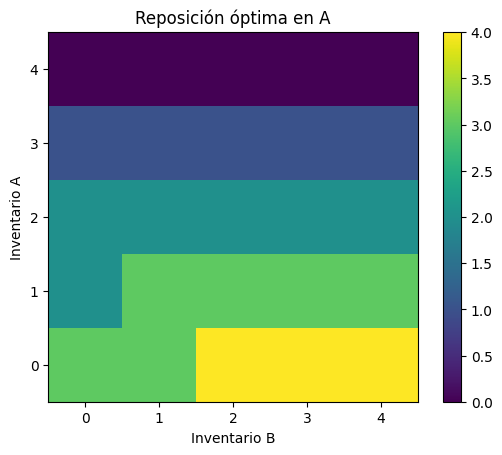

In [12]:
# mapa_A[i_A, i_B] = cantidad que la política óptima repone en A.
mapa_A = np.zeros((numero_niveles, numero_niveles))

for inventario_A in range(numero_niveles):

    for inventario_B in range(numero_niveles):

        estado_actual = inventario_A * numero_niveles + inventario_B

        mapa_A[inventario_A, inventario_B] = acciones[politica_optima[estado_actual]][0]

plt.imshow(mapa_A, origin="lower")
plt.xlabel("Inventario B")
plt.ylabel("Inventario A")
plt.title("Reposición óptima en A")
plt.colorbar()
plt.show()

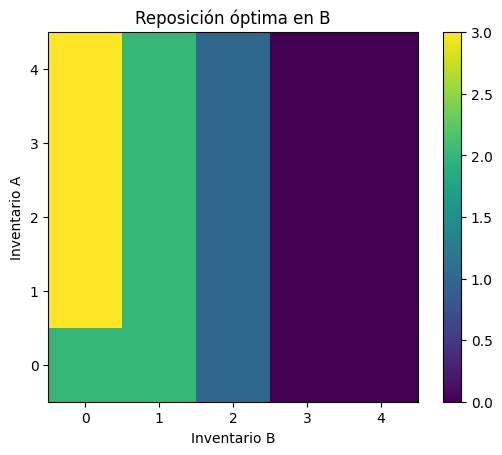

In [13]:
# mapa_B[i_A, i_B] = cantidad que la política óptima repone en B.
mapa_B = np.zeros((numero_niveles, numero_niveles))

for inventario_A in range(numero_niveles):

    for inventario_B in range(numero_niveles):

        estado_actual = inventario_A * numero_niveles + inventario_B

        mapa_B[inventario_A, inventario_B] = acciones[politica_optima[estado_actual]][1]

plt.imshow(mapa_B, origin="lower")
plt.xlabel("Inventario B")
plt.ylabel("Inventario A")
plt.title("Reposición óptima en B")
plt.colorbar()
plt.show()

---
## 5. Política base $(s,S)^2$

Usamos:

- A: $(s_A,S_A)=(1,3)$;
- B: $(s_B,S_B)=(1,3)$.

Es decir, si el inventario de un punto es menor o igual que $s$, se repone hasta $S$; si no, no se pide nada.

Si la suma pedida supera la capacidad del camión, se prioriza el punto con mayor razón $b_X/p_X$, donde $b_X$ es la penalización por faltante y $p_X$ el precio. Esa razón mide cuánto se pierde por cada unidad no atendida en relación con lo que se gana al venderla. Aquí $b_A/p_A=18/12=1.5$ y $b_B/p_B=22/15\approx1.47$, así que A tiene prioridad.

Primero se calcula la acción en dos estados a mano, uno sin conflicto y otro con conflicto de capacidad.

In [14]:
punto_reorden_A = 1
nivel_objetivo_A = 3

punto_reorden_B = 1
nivel_objetivo_B = 3

# Caso (1,2)
inventario_A = 1
inventario_B = 2

if inventario_A <= punto_reorden_A:
    cantidad_A = (
        nivel_objetivo_A - inventario_A
    )
else:
    cantidad_A = 0

if inventario_B <= punto_reorden_B:
    cantidad_B = (
        nivel_objetivo_B - inventario_B
    )
else:
    cantidad_B = 0

print(
    "Acción manual en (1,2):",
    (cantidad_A, cantidad_B)
)

# Caso (0,0)
inventario_A = 0
inventario_B = 0

cantidad_A_conflicto = (
    nivel_objetivo_A - inventario_A
)

cantidad_B_conflicto = (
    nivel_objetivo_B - inventario_B
)

if (
    cantidad_A_conflicto
    + cantidad_B_conflicto
    > capacidad_camion
):
    riesgo_A = (
        costo_faltante_A / precio_A
    )

    riesgo_B = (
        costo_faltante_B / precio_B
    )

    if riesgo_A >= riesgo_B:
        cantidad_A_conflicto = min(
            cantidad_A_conflicto,
            capacidad_camion
        )

        cantidad_B_conflicto = min(
            cantidad_B_conflicto,
            capacidad_camion
            - cantidad_A_conflicto
        )

    else:
        cantidad_B_conflicto = min(
            cantidad_B_conflicto,
            capacidad_camion
        )

        cantidad_A_conflicto = min(
            cantidad_A_conflicto,
            capacidad_camion
            - cantidad_B_conflicto
        )

print(
    "Acción manual en (0,0):",
    (
        cantidad_A_conflicto,
        cantidad_B_conflicto
    )
)

Acción manual en (1,2): (2, 0)
Acción manual en (0,0): (3, 2)


Ahora se aplica la misma regla en los 25 estados.

In [15]:
politica_base = np.zeros(numero_estados, dtype=int)

for estado_actual in range(numero_estados):

    inventario_A = estado_actual // numero_niveles
    inventario_B = estado_actual % numero_niveles

    if inventario_A <= punto_reorden_A:
        cantidad_A = nivel_objetivo_A - inventario_A
    else:
        cantidad_A = 0

    if inventario_B <= punto_reorden_B:
        cantidad_B = nivel_objetivo_B - inventario_B
    else:
        cantidad_B = 0

    # Si los dos pedidos no caben en el camión, el punto prioritario
    # recibe su pedido completo y el otro recibe lo que sobra.
    if cantidad_A + cantidad_B > capacidad_camion:

        riesgo_A = costo_faltante_A / precio_A
        riesgo_B = costo_faltante_B / precio_B

        if riesgo_A >= riesgo_B:
            cantidad_A = min(cantidad_A, capacidad_camion)
            cantidad_B = min(cantidad_B, capacidad_camion - cantidad_A)
        else:
            cantidad_B = min(cantidad_B, capacidad_camion)
            cantidad_A = min(cantidad_A, capacidad_camion - cantidad_B)

    politica_base[estado_actual] = indice_de_accion[cantidad_A, cantidad_B]

print("Acción de la regla en (1,2):", acciones[politica_base[1 * numero_niveles + 2]])
print("Acción de la regla en (0,0):", acciones[politica_base[0]])

Acción de la regla en (1,2): (2, 0)
Acción de la regla en (0,0): (3, 2)


### Evaluación exacta de una política

Para una política estacionaria $\pi$:

$$
(I-\gamma P^\pi)V^\pi=r^\pi.
$$

In [16]:
# P^π y r^π: para cada estado se toma la fila y el retorno de la acción elegida.
matriz_politica = np.zeros((numero_estados, numero_estados))
retorno_politica = np.zeros(numero_estados)

for estado_actual in range(numero_estados):

    accion_elegida = politica_base[estado_actual]

    matriz_politica[estado_actual, :] = matrices_transicion[accion_elegida][estado_actual, :]
    retorno_politica[estado_actual] = retornos[estado_actual, accion_elegida]

valor_base = np.linalg.solve(
    np.eye(numero_estados) - gamma * matriz_politica,
    retorno_politica
)

print("V_base(0,0):", round(valor_base[estado_cero], 2))
print("V(0,0) de VI:", round(valor_vi[estado_cero], 2))

V_base(0,0): 517.79
V(0,0) de VI: 590.14


---
## 6. Rollout de un paso

Calculamos:

$$
Q^{(1)}(s,a)
=
r(s,a)
+
\gamma
\sum_{s'}
P(s'|s,a)V^{\pi_0}(s').
$$

Después elegimos la acción con mayor valor en cada estado.

In [17]:
# Q^(1)(s,a) = r(s,a) + γ Σ P(s'|s,a) V_base(s'), solo para pares factibles.
valores_rollout_1 = np.full((numero_estados, numero_acciones), penalizacion_infactible)

for estado_actual in range(numero_estados):

    for accion_actual in range(numero_acciones):

        if factibilidad[estado_actual, accion_actual]:

            continuacion = 0.0

            for estado_siguiente in range(numero_estados):

                continuacion = (
                    continuacion
                    + matrices_transicion[accion_actual][estado_actual, estado_siguiente]
                    * valor_base[estado_siguiente]
                )

            valores_rollout_1[estado_actual, accion_actual] = (
                retornos[estado_actual, accion_actual] + gamma * continuacion
            )


# En cada estado: la mejor acción (política rollout-1) y su valor (respaldo T V_base).
politica_rollout_1 = np.zeros(numero_estados, dtype=int)
valor_respaldo_1 = np.zeros(numero_estados)

for estado_actual in range(numero_estados):

    mejor_valor = penalizacion_infactible
    mejor_accion = 0

    for accion_actual in range(numero_acciones):

        if valores_rollout_1[estado_actual, accion_actual] > mejor_valor:
            mejor_valor = valores_rollout_1[estado_actual, accion_actual]
            mejor_accion = accion_actual

    politica_rollout_1[estado_actual] = mejor_accion
    valor_respaldo_1[estado_actual] = mejor_valor

print("Acción rollout-1 en (0,0):", acciones[politica_rollout_1[estado_cero]])

Acción rollout-1 en (0,0): (3, 2)


## 7. Rollout de dos pasos

El vector `valor_respaldo_1` es $T V^{\pi_0}$. No es la evaluación exacta de rollout-1. Lo utilizamos como continuación para realizar un segundo respaldo.

In [18]:
# Q^(2)(s,a) = r(s,a) + γ Σ P(s'|s,a) (T V_base)(s').
valores_rollout_2 = np.full((numero_estados, numero_acciones), penalizacion_infactible)

for estado_actual in range(numero_estados):

    for accion_actual in range(numero_acciones):

        if factibilidad[estado_actual, accion_actual]:

            continuacion = 0.0

            for estado_siguiente in range(numero_estados):

                continuacion = (
                    continuacion
                    + matrices_transicion[accion_actual][estado_actual, estado_siguiente]
                    * valor_respaldo_1[estado_siguiente]
                )

            valores_rollout_2[estado_actual, accion_actual] = (
                retornos[estado_actual, accion_actual] + gamma * continuacion
            )


politica_rollout_2 = np.zeros(numero_estados, dtype=int)

for estado_actual in range(numero_estados):

    mejor_valor = penalizacion_infactible
    mejor_accion = 0

    for accion_actual in range(numero_acciones):

        if valores_rollout_2[estado_actual, accion_actual] > mejor_valor:
            mejor_valor = valores_rollout_2[estado_actual, accion_actual]
            mejor_accion = accion_actual

    politica_rollout_2[estado_actual] = mejor_accion

print("Acción rollout-2 en (0,0):", acciones[politica_rollout_2[estado_cero]])

Acción rollout-2 en (0,0): (3, 2)


### Rollout de $k$ pasos

El patrón es siempre el mismo: partir de $V^{\pi_0}$, aplicar $k-1$ respaldos de Bellman y tomar la acción greedy respecto del resultado. El siguiente ciclo lo hace para $k=1,2,3,4$ y guarda cada política en una lista. Las dos primeras deben coincidir con las calculadas arriba.

In [19]:
PROFUNDIDADES = [1, 2, 3, 4]

politicas_rollout = []

for indice_profundidad in range(len(PROFUNDIDADES)):

    numero_pasos = PROFUNDIDADES[indice_profundidad]

    valor_continuacion = valor_base.copy()

    # Se aplican numero_pasos - 1 respaldos y luego un último paso para elegir la acción.
    # En el último paso (paso == numero_pasos - 1) se guarda la acción greedy.
    politica = np.zeros(numero_estados, dtype=int)

    for paso in range(numero_pasos):

        valor_nuevo = np.zeros(numero_estados)

        for estado_actual in range(numero_estados):

            mejor_valor = penalizacion_infactible
            mejor_accion = 0

            for accion_actual in range(numero_acciones):

                if factibilidad[estado_actual, accion_actual]:

                    continuacion = 0.0

                    for estado_siguiente in range(numero_estados):

                        continuacion = (
                            continuacion
                            + matrices_transicion[accion_actual][estado_actual, estado_siguiente]
                            * valor_continuacion[estado_siguiente]
                        )

                    valor_accion = retornos[estado_actual, accion_actual] + gamma * continuacion

                    if valor_accion > mejor_valor:
                        mejor_valor = valor_accion
                        mejor_accion = accion_actual

            valor_nuevo[estado_actual] = mejor_valor
            politica[estado_actual] = mejor_accion

        valor_continuacion = valor_nuevo.copy()

    politicas_rollout.append(politica)


print("Rollout-1 coincide:", np.array_equal(politica_rollout_1, politicas_rollout[0]))
print("Rollout-2 coincide:", np.array_equal(politica_rollout_2, politicas_rollout[1]))

Rollout-1 coincide: True
Rollout-2 coincide: True


### Evaluación exacta y mejora

Cada política se evalúa con el sistema lineal. La comparación de cualquier rollout contra la política base corresponde a la garantía teórica. La comparación entre profundidades, y contra la política de VI, se reporta como un resultado observado en ColdLink.

In [20]:
# Políticas a evaluar: VI, base y rollout de 1 a 4 pasos.
nombres_evaluacion = ["VI", "Base", "Rollout-1", "Rollout-2", "Rollout-3", "Rollout-4"]

politicas_evaluacion = [politica_optima, politica_base]

for indice_profundidad in range(len(PROFUNDIDADES)):
    politicas_evaluacion.append(politicas_rollout[indice_profundidad])

# valores_exactos[i, s] = valor exacto de la política i en el estado s.
valores_exactos = np.zeros((len(politicas_evaluacion), numero_estados))

for indice_politica in range(len(politicas_evaluacion)):

    politica = politicas_evaluacion[indice_politica]

    matriz_politica = np.zeros((numero_estados, numero_estados))
    retorno_politica = np.zeros(numero_estados)

    for estado_actual in range(numero_estados):

        accion_elegida = politica[estado_actual]

        matriz_politica[estado_actual, :] = matrices_transicion[accion_elegida][estado_actual, :]
        retorno_politica[estado_actual] = retornos[estado_actual, accion_elegida]

    valores_exactos[indice_politica, :] = np.linalg.solve(
        np.eye(numero_estados) - gamma * matriz_politica,
        retorno_politica
    )

valor_optimo_exacto = valores_exactos[0, :]


print("Política   | V(0,0) | ¿>= base en todo s? | ¿<= VI en todo s? | estados distintos de VI")

for indice_politica in range(len(politicas_evaluacion)):

    mejora_base = True
    debajo_optimo = True
    estados_diferentes = 0

    for estado_actual in range(numero_estados):

        if valores_exactos[indice_politica, estado_actual] < valor_base[estado_actual] - 0.000001:
            mejora_base = False

        if valores_exactos[indice_politica, estado_actual] > valor_optimo_exacto[estado_actual] + 0.000001:
            debajo_optimo = False

        if politicas_evaluacion[indice_politica][estado_actual] != politica_optima[estado_actual]:
            estados_diferentes = estados_diferentes + 1

    print(
        nombres_evaluacion[indice_politica].ljust(10), "|",
        str(round(valores_exactos[indice_politica, estado_cero], 2)).rjust(6), "|",
        str(mejora_base).rjust(19), "|",
        str(debajo_optimo).rjust(17), "|",
        estados_diferentes
    )

Política   | V(0,0) | ¿>= base en todo s? | ¿<= VI en todo s? | estados distintos de VI
VI         | 590.14 |                True |              True | 0
Base       | 517.79 |                True |              True | 18
Rollout-1  | 576.47 |                True |              True | 17
Rollout-2  | 590.14 |                True |              True | 0
Rollout-3  | 590.14 |                True |              True | 0
Rollout-4  | 590.14 |                True |              True | 0


**Lectura.**

- **Todas las políticas rollout mejoran a la base en todos los estados**, como garantiza la teoría. Rollout-1 sube $V(0,0)$ de 517.79 a 576.47.
- **Rollout-1 todavía no es óptima:** difiere de la política de VI en 17 de los 25 estados.
- **Con dos pasos, rollout ya coincide con VI en los 25 estados**, y más profundidad no cambia nada. Que rollout-2 sea mejor que rollout-1 es un resultado de ColdLink, no una garantía general.
- Ninguna política supera a la de VI, lo que confirma que VI encontró la política óptima.

---
## 8. Benchmarking mediante escenarios comunes

Todas las políticas fueron diseñadas con retorno descontado. Por coherencia, la simulación evalúa:

$$
\sum_{t=0}^{T-1}\gamma^t r_t.
$$

En ColdLink el valor exacto de cada política ya se conoce, así que la simulación sirve para verificarlo y para practicar el procedimiento que se usa cuando el modelo es demasiado grande para resolver el sistema lineal.

Primero generamos una sola colección de demandas y la reutilizamos para todas las políticas. De esta manera, las diferencias entre políticas pueden analizarse con intervalos de confianza **emparejados**.

In [21]:
numero_simulaciones = 2000
numero_periodos = 100
semilla = 42

generador = np.random.default_rng(
    semilla
)

escenarios_demanda_A = (
    generador.binomial(
        numero_ensayos_A,
        probabilidad_exito_A,
        size=(
            numero_simulaciones,
            numero_periodos
        )
    )
)

escenarios_demanda_B = (
    generador.binomial(
        numero_ensayos_B,
        probabilidad_exito_B,
        size=(
            numero_simulaciones,
            numero_periodos
        )
    )
)

print(
    "Escenarios generados:",
    escenarios_demanda_A.shape
)

Escenarios generados: (2000, 100)


### Un episodio explícito

Antes de simular todas las políticas, simulamos diez períodos bajo la política base usando el primer escenario.

In [22]:
estado_actual = estado_cero
retorno_acumulado = 0.0
periodos_demostracion = 10

for periodo in range(periodos_demostracion):

    indice_accion = politica_base[estado_actual]

    cantidad_A = acciones[indice_accion][0]
    cantidad_B = acciones[indice_accion][1]

    inventario_A = estado_actual // numero_niveles
    inventario_B = estado_actual % numero_niveles

    inventario_disponible_A = inventario_A + cantidad_A
    inventario_disponible_B = inventario_B + cantidad_B

    demanda_A = int(escenarios_demanda_A[0, periodo])
    demanda_B = int(escenarios_demanda_B[0, periodo])

    ingreso = (
        precio_A * min(inventario_disponible_A, demanda_A)
        + precio_B * min(inventario_disponible_B, demanda_B)
    )

    costo_reposicion = (
        costo_reposicion_A * cantidad_A
        + costo_reposicion_B * cantidad_B
    )

    inventario_final_A = max(0, inventario_disponible_A - demanda_A)
    inventario_final_B = max(0, inventario_disponible_B - demanda_B)

    faltante_A = max(0, demanda_A - inventario_disponible_A)
    faltante_B = max(0, demanda_B - inventario_disponible_B)

    retorno_periodo = (
        ingreso
        - costo_reposicion
        - costo_almacenamiento_A * inventario_final_A
        - costo_almacenamiento_B * inventario_final_B
        - costo_faltante_A * faltante_A
        - costo_faltante_B * faltante_B
    )

    retorno_acumulado = retorno_acumulado + gamma ** periodo * retorno_periodo

    estado_actual = inventario_final_A * numero_niveles + inventario_final_B

    print(
        "Período", periodo,
        "- acción:", (cantidad_A, cantidad_B),
        "- demanda:", (demanda_A, demanda_B),
        "- retorno:", round(retorno_periodo, 2)
    )

print("Retorno descontado acumulado:", round(retorno_acumulado, 2))

Período 0 - acción: (3, 2) - demanda: (3, 2) - retorno: 44.0
Período 1 - acción: (3, 2) - demanda: (2, 2) - retorno: 31.0
Período 2 - acción: (2, 3) - demanda: (3, 1) - retorno: 26.0
Período 3 - acción: (3, 0) - demanda: (3, 2) - retorno: 54.0
Período 4 - acción: (3, 2) - demanda: (1, 1) - retorno: 2.0
Período 5 - acción: (0, 2) - demanda: (4, 2) - retorno: 7.0
Período 6 - acción: (3, 2) - demanda: (3, 2) - retorno: 43.0
Período 7 - acción: (3, 2) - demanda: (3, 1) - retorno: 27.0
Período 8 - acción: (3, 0) - demanda: (1, 2) - retorno: 28.0
Período 9 - acción: (0, 3) - demanda: (2, 2) - retorno: 38.0
Retorno descontado acumulado: 243.25


### Simulación de todas las políticas

Se repite el mismo cálculo del episodio para cada política, cada escenario y los 100 períodos. Todas parten de $(0,0)$ y enfrentan exactamente las mismas demandas.

Al final se compara la media simulada con el valor exacto $V(0,0)$. La simulación se corta en $T=100$ períodos, así que deja por fuera una parte del orden de $\gamma^{100}\approx 0.006$ del valor total: la media simulada debe quedar unas pocas unidades por debajo del valor exacto.

In [23]:
politicas = [
    politica_optima,
    politica_base,
    politica_rollout_1,
    politica_rollout_2
]

nombres_politicas = [
    "VI",
    "Heurística",
    "Rollout-1",
    "Rollout-2"
]

# Posición de cada política en valores_exactos (para comparar con lo simulado).
indices_en_evaluacion = [0, 1, 2, 3]

numero_politicas = len(politicas)

resultados_simulacion = np.zeros((numero_politicas, numero_simulaciones))
medias = np.zeros(numero_politicas)
errores_estandar = np.zeros(numero_politicas)

for indice_politica in range(numero_politicas):

    politica = politicas[indice_politica]

    for simulacion in range(numero_simulaciones):

        estado_actual = estado_cero
        retorno_acumulado = 0.0

        for periodo in range(numero_periodos):

            indice_accion = politica[estado_actual]

            cantidad_A = acciones[indice_accion][0]
            cantidad_B = acciones[indice_accion][1]

            inventario_disponible_A = estado_actual // numero_niveles + cantidad_A
            inventario_disponible_B = estado_actual % numero_niveles + cantidad_B

            demanda_A = escenarios_demanda_A[simulacion, periodo]
            demanda_B = escenarios_demanda_B[simulacion, periodo]

            inventario_final_A = max(0, inventario_disponible_A - demanda_A)
            inventario_final_B = max(0, inventario_disponible_B - demanda_B)

            faltante_A = max(0, demanda_A - inventario_disponible_A)
            faltante_B = max(0, demanda_B - inventario_disponible_B)

            retorno_periodo = (
                precio_A * min(inventario_disponible_A, demanda_A)
                + precio_B * min(inventario_disponible_B, demanda_B)
                - costo_reposicion_A * cantidad_A
                - costo_reposicion_B * cantidad_B
                - costo_almacenamiento_A * inventario_final_A
                - costo_almacenamiento_B * inventario_final_B
                - costo_faltante_A * faltante_A
                - costo_faltante_B * faltante_B
            )

            retorno_acumulado = retorno_acumulado + gamma ** periodo * retorno_periodo

            estado_actual = inventario_final_A * numero_niveles + inventario_final_B

        resultados_simulacion[indice_politica, simulacion] = retorno_acumulado

    medias[indice_politica] = resultados_simulacion[indice_politica, :].mean()

    errores_estandar[indice_politica] = (
        resultados_simulacion[indice_politica, :].std(ddof=1)
        / np.sqrt(numero_simulaciones)
    )

    print(
        nombres_politicas[indice_politica].ljust(10),
        "- media:", round(medias[indice_politica], 2),
        "- IC 95%:",
        (
            float(round(medias[indice_politica] - 1.96 * errores_estandar[indice_politica], 2)),
            float(round(medias[indice_politica] + 1.96 * errores_estandar[indice_politica], 2))
        ),
        "- V(0,0) exacto:",
        round(valores_exactos[indices_en_evaluacion[indice_politica], estado_cero], 2)
    )

VI         - media: 587.34 - IC 95%: (585.55, 589.13) - V(0,0) exacto: 590.14


Heurística - media: 515.17 - IC 95%: (513.15, 517.18) - V(0,0) exacto: 517.79


Rollout-1  - media: 573.51 - IC 95%: (571.82, 575.2) - V(0,0) exacto: 576.47


Rollout-2  - media: 587.34 - IC 95%: (585.55, 589.13) - V(0,0) exacto: 590.14


**Lectura.** Las medias simuladas quedan entre 2.6 y 3.0 unidades por debajo del valor exacto. Es el tamaño esperado de la parte truncada: después de 100 períodos todavía faltaría sumar alrededor de $\gamma^{100}V\approx 0.006\times 590\approx 3.5$. Por eso, por ejemplo, el intervalo marginal de VI no contiene 590.14: la simulación estima el retorno descontado de 100 períodos, no el de horizonte infinito. Para comparar políticas entre sí esto no importa, porque el truncamiento afecta a todas casi por igual.

VI y rollout-2 producen exactamente los mismos resultados porque son la misma política.

### Intervalos emparejados de las diferencias

Para cada política calculamos:

$$
D_i
=
R_i^\pi
-
R_i^{\text{heurística}}.
$$

Si el intervalo de confianza de la diferencia no contiene cero, detectamos una diferencia bajo los escenarios evaluados.

In [24]:
indice_heuristica = 1

for indice_politica in range(
    numero_politicas
):

    if indice_politica != indice_heuristica:

        diferencias = (
            resultados_simulacion[
                indice_politica, :
            ]
            - resultados_simulacion[
                indice_heuristica, :
            ]
        )

        diferencia_media = (
            diferencias.mean()
        )

        error_diferencia = (
            diferencias.std(ddof=1)
            / np.sqrt(numero_simulaciones)
        )

        limite_inferior = (
            diferencia_media
            - 1.96 * error_diferencia
        )

        limite_superior = (
            diferencia_media
            + 1.96 * error_diferencia
        )

        contiene_cero = (
            limite_inferior <= 0
            and limite_superior >= 0
        )

        print(
            nombres_politicas[
                indice_politica
            ],
            "menos Heurística:",
            round(diferencia_media, 2),
            "- IC 95%:",
            (
                float(round(limite_inferior, 2)),
                float(round(limite_superior, 2))
            ),
            "- contiene cero:",
            contiene_cero
        )

VI menos Heurística: 72.17 - IC 95%: (70.53, 73.81) - contiene cero: False
Rollout-1 menos Heurística: 58.34 - IC 95%: (57.07, 59.62) - contiene cero: False
Rollout-2 menos Heurística: 72.17 - IC 95%: (70.53, 73.81) - contiene cero: False


**Lectura.** Ningún intervalo contiene cero: VI, rollout-1 y rollout-2 superan a la heurística en los escenarios evaluados. Las diferencias simuladas son consistentes con las exactas: $590.14-517.79=72.35$ frente a 72.17 simulado, y $576.47-517.79=58.68$ frente a 58.34.

### 🎨 Visualización proporcionada

Esta gráfica resume las medias y sus intervalos marginales. La decisión estadística se basa en los intervalos emparejados calculados arriba, no en el solapamiento visual de las barras.

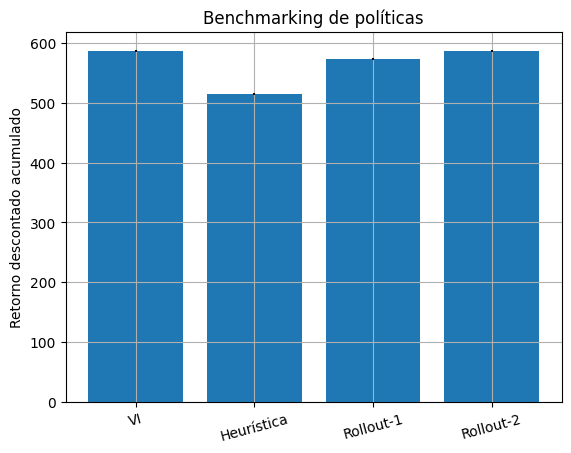

In [25]:
errores_95 = (
    1.96 * errores_estandar
)

plt.bar(
    nombres_politicas,
    medias,
    yerr=errores_95
)

plt.ylabel(
    "Retorno descontado acumulado"
)

plt.title(
    "Benchmarking de políticas"
)

plt.xticks(rotation=15)
plt.grid()
plt.show()

---
## 9. Ejercicio: LogiMax S.A.S. — tres zonas

LogiMax atiende Norte, Sur y Centro con un camión de capacidad 8.

| Zona | Demanda | Precio | Reposición | Almacenamiento | Faltante |
|:---|:---:|---:|---:|---:|---:|
| Norte | $\operatorname{Bin}(5,0.45)$ | 14 | 5 | 1.5 | 20 |
| Sur | $\operatorname{Bin}(4,0.60)$ | 18 | 6 | 2.0 | 25 |
| Centro | $\operatorname{Bin}(3,0.70)$ | 16 | 5 | 1.5 | 22 |

Cada zona puede almacenar de 0 a 3 unidades. Por tanto, hay:

$$
4^3=64
$$

estados.

La codificación es:

$$
\operatorname{indice}(i_N,i_S,i_C)
=
16i_N+4i_S+i_C.
$$

Use $\gamma=0.95$.

### Checkpoints

1. Escriba la codificación del estado y su inversa con `//` y `%`. Por ejemplo, $i_N$ = `indice // 16`.
2. Construya las acciones $(q_N,q_S,q_C)$ mediante tres ciclos y la condición $q_N+q_S+q_C\leq8$, junto con una tabla `indice_de_accion[q_N, q_S, q_C]`.
3. Construya cada zona por separado con un mismo ciclo, como en ColdLink, guardando los parámetros en listas con una posición por zona.
4. Antes de combinar todo, calcule manualmente una transición conjunta como producto de tres probabilidades.
5. Construya:
   - una lista de matrices de transición;
   - una matriz de retornos;
   - una matriz de factibilidad.
6. Resuelva el MDP con `dtmdp` (iteración de valor). Con 64 estados y 63 acciones puede tardar algunos minutos.
7. Implemente la heurística $(s,S)^3$:
   - Norte: $(1,3)$;
   - Sur: $(1,3)$;
   - Centro: $(1,2)$.
8. Cuando la capacidad sea insuficiente, asigne unidades priorizando las zonas con mayor razón $b/p$.
9. Evalúe exactamente la heurística y la política de VI con el sistema lineal.
10. Calcule las políticas rollout con uno y dos pasos.
11. Verifique la mejora de rollout-1 respecto de la base. Reporte por separado lo que ocurra entre rollout-2 y rollout-1.
12. Use escenarios comunes, retorno descontado e intervalos emparejados para comparar las políticas.

### Código permitido

Utilice únicamente:

- ciclos ordinarios;
- condicionales;
- listas y matrices sencillas;
- `jmarkov` para iteración de valor.

No utilice:

- definiciones de funciones;
- `zip`;
- `enumerate`;
- comprensiones;
- funciones `lambda`;
- máscaras booleanas.

### Referencias manuales mínimas

Antes de aceptar código generado por IA, compruebe:

- una recompensa de una zona;
- una fila de transición marginal;
- una probabilidad conjunta;
- la suma de una fila de la matriz conjunta;
- una acción de la heurística en un estado sin conflicto;
- una acción de la heurística en un estado con conflicto.

El reto principal es el tamaño del modelo. La lógica de cada paso debe ser la misma utilizada en ColdLink.

---
<small>Universidad de los Andes · Departamento de Ingeniería Industrial · Modelos de Decisión en el Tiempo</small>